In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/X-IDS"

RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
import zipfile
import os

ZIP_PATH = os.path.join(RAW_DIR, "MachineLearningCSV.zip")
EXTRACT_DIR = os.path.join(RAW_DIR, "extracted")

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import glob

csv_files = glob.glob(
    os.path.join(EXTRACT_DIR, "**", "*.csv"),
    recursive=True
)

print("Total CSV files:", len(csv_files))

for file in sorted(csv_files):
    print(os.path.basename(file))

Total CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
EXTRACT_DIR = "/content/drive/MyDrive/X-IDS/data/raw/extracted"

csv_files = glob.glob(
    os.path.join(EXTRACT_DIR, "**", "*.csv"),
    recursive=True
)

dataframes = {}

for file in sorted(csv_files):
    name = os.path.basename(file)

    df = pd.read_csv(file, low_memory=False)

    dataframes[name] = df

    print(name, "->", df.shape)

print("\nAll CSV files loaded successfully!")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv -> (225745, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv -> (286467, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv -> (191033, 79)
Monday-WorkingHours.pcap_ISCX.csv -> (529918, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv -> (288602, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv -> (170366, 79)
Tuesday-WorkingHours.pcap_ISCX.csv -> (445909, 79)
Wednesday-workingHours.pcap_ISCX.csv -> (692703, 79)

All CSV files loaded successfully!


In [ ]:
for name, df in dataframes.items():
    print("\nDataset:", name)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows: 225745
Columns: 79

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows: 286467
Columns: 79

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows: 191033
Columns: 79

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Rows: 529918
Columns: 79

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows: 288602
Columns: 79

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows: 170366
Columns: 79

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Rows: 445909
Columns: 79

Dataset: Wednesday-workingHours.pcap_ISCX.csv
Rows: 692703
Columns: 79


In [ ]:
dataset_summary = pd.DataFrame({
    "File": [name for name in dataframes],
    "Rows": [df.shape[0] for df in dataframes.values()],
    "Columns": [df.shape[1] for df in dataframes.values()]
})

display(dataset_summary)

,File,Rows,Columns
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,79
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79
3,Monday-WorkingHours.pcap_ISCX.csv,529918,79
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,79
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,79
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79
7,Wednesday-workingHours.pcap_ISCX.csv,692703,79


In [ ]:
for name, df in dataframes.items():
    print("\n\nDataset:", name)
    print(df.dtypes.value_counts())
    print("\nColumn names:")
    print(df.columns.tolist())



Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
int64      54
float64    24
object      1
Name: count, dtype: int64

Column names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Le

In [ ]:
sample_df = next(iter(dataframes.values()))

numerical_features = sample_df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = sample_df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 78
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK F

In [ ]:
for name, df in dataframes.items():
    missing = df.isnull().sum().sum()

    print(name)
    print("Total missing values:", missing)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total missing values: 4
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Total missing values: 15
Friday-WorkingHours-Morning.pcap_ISCX.csv
Total missing values: 28
Monday-WorkingHours.pcap_ISCX.csv
Total missing values: 64
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Total missing values: 18
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Total missing values: 20
Tuesday-WorkingHours.pcap_ISCX.csv
Total missing values: 201
Wednesday-workingHours.pcap_ISCX.csv
Total missing values: 1008


In [ ]:
for name, df in dataframes.items():

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    print("\nDataset:", name)
    print(missing)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Flow Bytes/s    4
dtype: int64

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Flow Bytes/s    15
dtype: int64

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Flow Bytes/s    28
dtype: int64

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Flow Bytes/s    64
dtype: int64

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Flow Bytes/s    18
dtype: int64

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Flow Bytes/s    20
dtype: int64

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Flow Bytes/s    201
dtype: int64

Dataset: Wednesday-workingHours.pcap_ISCX.csv
Flow Bytes/s    1008
dtype: int64


In [ ]:
for name, df in dataframes.items():

    duplicates = df.duplicated().sum()

    print(name)
    print("Duplicate records:", duplicates)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Duplicate records: 2633
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Duplicate records: 72353
Friday-WorkingHours-Morning.pcap_ISCX.csv
Duplicate records: 6888
Monday-WorkingHours.pcap_ISCX.csv
Duplicate records: 26935
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Duplicate records: 35630
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Duplicate records: 6066
Tuesday-WorkingHours.pcap_ISCX.csv
Duplicate records: 24065
Wednesday-workingHours.pcap_ISCX.csv
Duplicate records: 81909


In [ ]:
for name, df in dataframes.items():

    numeric_df = df.select_dtypes(include=np.number)

    positive_inf = np.isposinf(numeric_df).sum().sum()
    negative_inf = np.isneginf(numeric_df).sum().sum()

    print("\nDataset:", name)
    print("Positive infinity:", positive_inf)
    print("Negative infinity:", negative_inf)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Positive infinity: 64
Negative infinity: 0

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Positive infinity: 727
Negative infinity: 0

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Positive infinity: 216
Negative infinity: 0

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Positive infinity: 810
Negative infinity: 0

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Positive infinity: 396
Negative infinity: 0

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Positive infinity: 250
Negative infinity: 0

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Positive infinity: 327
Negative infinity: 0

Dataset: Wednesday-workingHours.pcap_ISCX.csv
Positive infinity: 1586
Negative infinity: 0


In [ ]:
all_labels = set()

for name, df in dataframes.items():

    label_col = next(
        col for col in df.columns
        if col.strip() == "Label"
    )

    labels = df[label_col].astype(str).str.strip()

    all_labels.update(labels.unique())

print("Total unique labels:", len(all_labels))

print("\nUnique attack labels:")

for label in sorted(all_labels):
    print(label)

Total unique labels: 15

Unique attack labels:
BENIGN
Bot
DDoS
DoS GoldenEye
DoS Hulk
DoS Slowhttptest
DoS slowloris
FTP-Patator
Heartbleed
Infiltration
PortScan
SSH-Patator
Web Attack � Brute Force
Web Attack � Sql Injection
Web Attack � XSS


In [ ]:
class_counts = {}

for name, df in dataframes.items():

    label_col = next(
        col for col in df.columns
        if col.strip() == "Label"
    )

    labels = df[label_col].astype(str).str.strip()

    counts = labels.value_counts()

    for label, count in counts.items():
        class_counts[label] = (
            class_counts.get(label, 0) + count
        )

class_distribution = pd.DataFrame(
    list(class_counts.items()),
    columns=["Attack Type", "Count"]
)

class_distribution = class_distribution.sort_values(
    by="Count",
    ascending=False
)

class_distribution["Percentage"] = (
    class_distribution["Count"] /
    class_distribution["Count"].sum()
) * 100

display(class_distribution)

,Attack Type,Count,Percentage
1,BENIGN,2273097,80.300366
10,DoS Hulk,231073,8.162981
2,PortScan,158930,5.614427
0,DDoS,128027,4.522735
11,DoS GoldenEye,10293,0.363615
8,FTP-Patator,7938,0.280421
9,SSH-Patator,5897,0.208320
12,DoS slowloris,5796,0.204752
13,DoS Slowhttptest,5499,0.194260
3,Bot,1966,0.069452


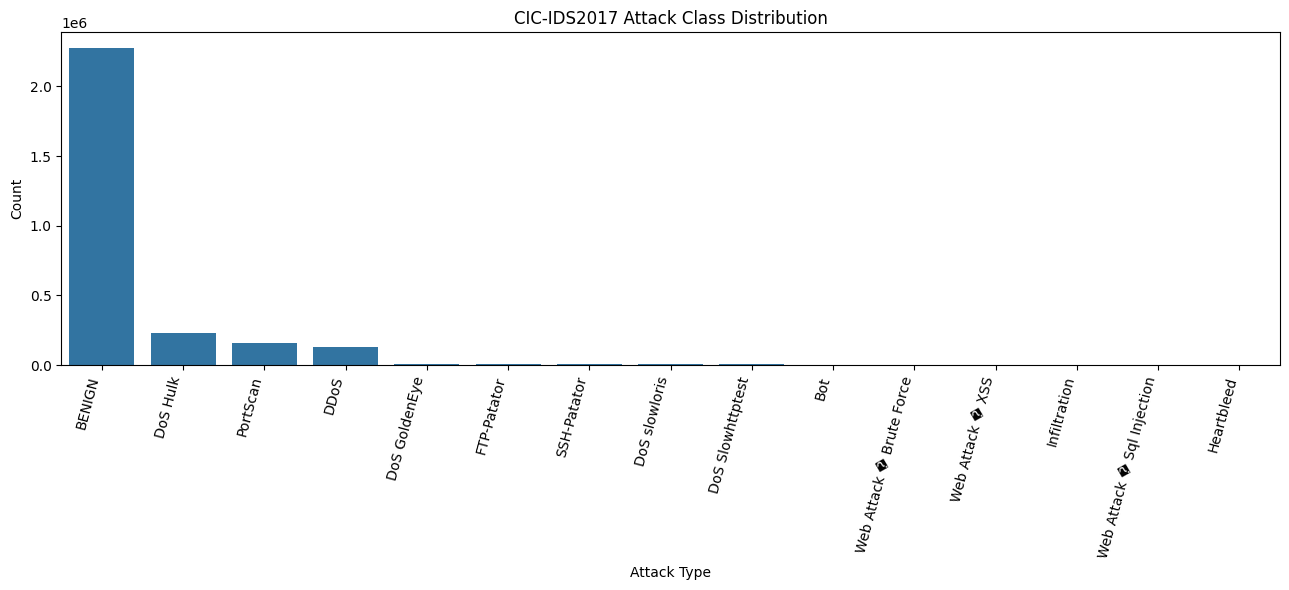

In [ ]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=class_distribution,
    x="Attack Type",
    y="Count"
)

plt.title("CIC-IDS2017 Attack Class Distribution")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
binary_counts = {
    "BENIGN": 0,
    "ATTACK": 0
}

for label, count in class_counts.items():

    if label == "BENIGN":
        binary_counts["BENIGN"] += count
    else:
        binary_counts["ATTACK"] += count

print(binary_counts)

{'BENIGN': 2273097, 'ATTACK': 557646}


In [ ]:
combined_sample = pd.concat(
    dataframes.values(),
    ignore_index=True
)

combined_sample.columns = combined_sample.columns.str.strip()

constant_features = [
    col for col in combined_sample.columns
    if combined_sample[col].nunique(dropna=False) <= 1
]

print("Constant features:", constant_features)

Constant features: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [ ]:
for name, df in dataframes.items():

    temp = df.copy()
    temp.columns = temp.columns.str.strip()

    feature_cols = [
        col for col in temp.columns
        if col != "Label"
    ]

    hashes = pd.util.hash_pandas_object(
        temp[feature_cols],
        index=False
    )

    check = pd.DataFrame({
        "hash": hashes,
        "Label": temp["Label"].astype(str).str.strip()
    })

    conflicts = (
        check.groupby("hash")["Label"]
        .nunique()
        .gt(1).sum()
    )

    print(name, ":", conflicts)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv : 0
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv : 0
Friday-WorkingHours-Morning.pcap_ISCX.csv : 0
Monday-WorkingHours.pcap_ISCX.csv : 0
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv : 0
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv : 0
Tuesday-WorkingHours.pcap_ISCX.csv : 0
Wednesday-workingHours.pcap_ISCX.csv : 48


In [ ]:
name = "Wednesday-workingHours.pcap_ISCX.csv"

df = dataframes[name].copy()
df.columns = df.columns.str.strip()

feature_cols = [col for col in df.columns if col != "Label"]

hashes = pd.util.hash_pandas_object(
    df[feature_cols], index=False
)

labels = df["Label"].astype(str).str.strip()

check = pd.DataFrame({
    "hash": hashes,
    "Label": labels
})

conflict_hashes = (
    check.groupby("hash")["Label"]
    .nunique()
)

conflict_hashes = conflict_hashes[
    conflict_hashes > 1
].index

conflict_rows = df.loc[
    hashes.isin(conflict_hashes)
]

print("Number of conflicting groups:", len(conflict_hashes))
print("Number of affected rows:", len(conflict_rows))

display(conflict_rows[["Label"]].value_counts().reset_index(
    name="Count"
))

display(conflict_rows.head(20))

Number of conflicting groups: 48
Number of affected rows: 1091


,Label,Count
0,DoS Hulk,1041
1,BENIGN,49
2,DoS slowloris,1


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
21090,80,193,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
26700,80,229,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DoS slowloris
34748,80,156,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
35554,80,199,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
36204,80,190,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
51675,80,961,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
74874,80,0,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,DoS Hulk
74996,80,0,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,DoS Hulk
75128,80,0,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,DoS Hulk
75361,80,994,2,0,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,DoS Hulk


In [ ]:
EDA_OUTPUT = os.path.join(PROJECT_DIR, "outputs")
os.makedirs(EDA_OUTPUT, exist_ok=True)

class_distribution.to_csv(
    os.path.join(EDA_OUTPUT, "class_distribution.csv"),
    index=False
)

print("Class distribution saved successfully!")

Class distribution saved successfully!


In [ ]:
# Create a summary of all conflicting groups

conflict_summary = (
    check[check["hash"].isin(conflict_hashes)]
    .groupby("hash")
    .agg(
        Total_Rows=("Label", "size"),
        Labels=("Label", lambda x: ", ".join(sorted(x.unique()))),
        Label_Counts=("Label", lambda x: str(x.value_counts().to_dict()))
    )
    .reset_index()
)

print("Total conflicting groups:", len(conflict_summary))

display(conflict_summary)

Total conflicting groups: 48


,hash,Total_Rows,Labels,Label_Counts
0,161063990953879959,2,"BENIGN, DoS Hulk","{'DoS Hulk': 1, 'BENIGN': 1}"
1,328060695582411814,8,"BENIGN, DoS Hulk","{'DoS Hulk': 7, 'BENIGN': 1}"
2,1552550319930799463,4,"BENIGN, DoS Hulk","{'DoS Hulk': 3, 'BENIGN': 1}"
3,1610286500228706310,10,"BENIGN, DoS Hulk","{'DoS Hulk': 9, 'BENIGN': 1}"
4,2676070763125964895,8,"BENIGN, DoS Hulk","{'DoS Hulk': 7, 'BENIGN': 1}"
5,3144997965457904433,11,"BENIGN, DoS Hulk","{'DoS Hulk': 10, 'BENIGN': 1}"
6,3566029670018468095,46,"BENIGN, DoS Hulk","{'DoS Hulk': 45, 'BENIGN': 1}"
7,4147361467433192379,2,"BENIGN, DoS Hulk","{'DoS Hulk': 1, 'BENIGN': 1}"
8,4368527496468821709,24,"BENIGN, DoS Hulk","{'DoS Hulk': 23, 'BENIGN': 1}"
9,4584068089211109402,9,"BENIGN, DoS Hulk","{'DoS Hulk': 8, 'BENIGN': 1}"


In [ ]:
# Display representative rows from each conflicting group

for h in conflict_hashes:
    group_indices = check.index[check["hash"] == h]

    print("\nConflicting Group")
    print("Labels:", labels.loc[group_indices].value_counts().to_dict())

    display(
        df.loc[group_indices, [
            "Destination Port",
            "Flow Duration",
            "Total Fwd Packets",
            "Total Backward Packets",
            "Total Length of Fwd Packets",
            "Label"
        ]]
    )


Conflicting Group
Labels: {'DoS Hulk': 1, 'BENIGN': 1}


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Label
266305,80,325,2,0,0,DoS Hulk
354594,80,325,2,0,0,BENIGN



Conflicting Group
Labels: {'DoS Hulk': 7, 'BENIGN': 1}


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Label
183491,80,265,2,0,0,DoS Hulk
213503,80,265,2,0,0,DoS Hulk
243749,80,265,2,0,0,DoS Hulk
281518,80,265,2,0,0,DoS Hulk
281677,80,265,2,0,0,DoS Hulk
292943,80,265,2,0,0,DoS Hulk
293037,80,265,2,0,0,DoS Hulk
431750,80,265,2,0,0,BENIGN



Conflicting Group
Labels: {'DoS Hulk': 3, 'BENIGN': 1}


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Label
191276,80,154,2,0,0,DoS Hulk
238685,80,154,2,0,0,DoS Hulk
327676,80,154,2,0,0,DoS Hulk
448536,80,154,2,0,0,BENIGN


... (86 outputs left out)


Conflicting Group
Labels: {'DoS Hulk': 3, 'BENIGN': 1}


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Label
107157,80,110,2,0,0,DoS Hulk
173460,80,110,2,0,0,DoS Hulk
180778,80,110,2,0,0,DoS Hulk
356157,80,110,2,0,0,BENIGN



Conflicting Group
Labels: {'DoS Hulk': 1, 'BENIGN': 1}


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Label
162118,80,126,2,0,0,DoS Hulk
355409,80,126,2,0,0,BENIGN


In [ ]:
conflict_summary.to_csv(
    os.path.join(EDA_OUTPUT, "conflicting_label_groups.csv"),
    index=False
)

print("Conflict analysis saved successfully!")

Conflict analysis saved successfully!


In [ ]:
constant_features = [
    'Bwd PSH Flags',
    'Bwd URG Flags',
    'Fwd Avg Bytes/Bulk',
    'Fwd Avg Packets/Bulk',
    'Fwd Avg Bulk Rate',
    'Bwd Avg Bytes/Bulk',
    'Bwd Avg Packets/Bulk',
    'Bwd Avg Bulk Rate'
]

for col in constant_features:
    print("\nFeature:", col)

    for name, df in dataframes.items():
        actual_col = next(c for c in df.columns if c.strip() == col)
        print(name, ":", df[actual_col].dropna().unique()[:5])


Feature: Bwd PSH Flags
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv : [0]
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv : [0]
Friday-WorkingHours-Morning.pcap_ISCX.csv : [0]
Monday-WorkingHours.pcap_ISCX.csv : [0]
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv : [0]
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv : [0]
Tuesday-WorkingHours.pcap_ISCX.csv : [0]
Wednesday-workingHours.pcap_ISCX.csv : [0]

Feature: Bwd URG Flags
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv : [0]
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv : [0]
Friday-WorkingHours-Morning.pcap_ISCX.csv : [0]
Monday-WorkingHours.pcap_ISCX.csv : [0]
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv : [0]
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv : [0]
Tuesday-WorkingHours.pcap_ISCX.csv : [0]
Wednesday-workingHours.pcap_ISCX.csv : [0]

Feature: Fwd Avg Bytes/Bulk
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv : [0]
Friday-WorkingHours-Afternoon-PortScan.pca

In [ ]:
constant_features = [
    'Bwd PSH Flags',
    'Bwd URG Flags',
    'Fwd Avg Bytes/Bulk',
    'Fwd Avg Packets/Bulk',
    'Fwd Avg Bulk Rate',
    'Bwd Avg Bytes/Bulk',
    'Bwd Avg Packets/Bulk',
    'Bwd Avg Bulk Rate'
]

constant_report = pd.DataFrame({
    "Feature": constant_features,
    "Observed_Value": [0] * len(constant_features),
    "Action": ["Remove during preprocessing"] * len(constant_features)
})

constant_report.to_csv(
    os.path.join(EDA_OUTPUT, "constant_features.csv"),
    index=False
)

display(constant_report)

,Feature,Observed_Value,Action
0,Bwd PSH Flags,0,Remove during preprocessing
1,Bwd URG Flags,0,Remove during preprocessing
2,Fwd Avg Bytes/Bulk,0,Remove during preprocessing
3,Fwd Avg Packets/Bulk,0,Remove during preprocessing
4,Fwd Avg Bulk Rate,0,Remove during preprocessing
5,Bwd Avg Bytes/Bulk,0,Remove during preprocessing
6,Bwd Avg Packets/Bulk,0,Remove during preprocessing
7,Bwd Avg Bulk Rate,0,Remove during preprocessing


In [ ]:
# Inspect the cleaned column names
sample_df = next(iter(dataframes.values())).copy()
sample_df.columns = sample_df.columns.str.strip()

print("Total columns:", len(sample_df.columns))
print("\nAll dataset columns:")

for i, col in enumerate(sample_df.columns, 1):
    print(i, col)

# Check for graph-related attributes
graph_columns = [
    col for col in sample_df.columns
    if any(term in col.lower() for term in [
        "source", "destination", "ip", "timestamp", "time", "protocol"
    ])
]

print("\nPotential graph-related columns:", graph_columns)

Total columns: 79

All dataset columns:
1 Destination Port
2 Flow Duration
3 Total Fwd Packets
4 Total Backward Packets
5 Total Length of Fwd Packets
6 Total Length of Bwd Packets
7 Fwd Packet Length Max
8 Fwd Packet Length Min
9 Fwd Packet Length Mean
10 Fwd Packet Length Std
11 Bwd Packet Length Max
12 Bwd Packet Length Min
13 Bwd Packet Length Mean
14 Bwd Packet Length Std
15 Flow Bytes/s
16 Flow Packets/s
17 Flow IAT Mean
18 Flow IAT Std
19 Flow IAT Max
20 Flow IAT Min
21 Fwd IAT Total
22 Fwd IAT Mean
23 Fwd IAT Std
24 Fwd IAT Max
25 Fwd IAT Min
26 Bwd IAT Total
27 Bwd IAT Mean
28 Bwd IAT Std
29 Bwd IAT Max
30 Bwd IAT Min
31 Fwd PSH Flags
32 Bwd PSH Flags
33 Fwd URG Flags
34 Bwd URG Flags
35 Fwd Header Length
36 Bwd Header Length
37 Fwd Packets/s
38 Bwd Packets/s
39 Min Packet Length
40 Max Packet Length
41 Packet Length Mean
42 Packet Length Std
43 Packet Length Variance
44 FIN Flag Count
45 SYN Flag Count
46 RST Flag Count
47 PSH Flag Count
48 ACK Flag Count
49 URG Flag Count
50 

In [ ]:
for name, df in dataframes.items():

    temp = df.copy()
    temp.columns = temp.columns.str.strip()

    col1 = temp["Fwd Header Length"]
    col2 = temp["Fwd Header Length.1"]

    print(
        name,
        "Identical:",
        col1.equals(col2),
        "| Different values:",
        (col1 != col2).sum()
    )

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv Identical: True | Different values: 0
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv Identical: True | Different values: 0
Friday-WorkingHours-Morning.pcap_ISCX.csv Identical: True | Different values: 0
Monday-WorkingHours.pcap_ISCX.csv Identical: True | Different values: 0
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv Identical: True | Different values: 0
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv Identical: True | Different values: 0
Tuesday-WorkingHours.pcap_ISCX.csv Identical: True | Different values: 0
Wednesday-workingHours.pcap_ISCX.csv Identical: True | Different values: 0


In [ ]:
eda_summary = {
    "Total_Records": 2830743,
    "Total_Columns": 79,
    "Numerical_Features": 78,
    "Target_Column": "Label",
    "Unique_Labels": 15,
    "Missing_Values": 1358,
    "Positive_Infinity": 4376,
    "Negative_Infinity": 0,
    "Duplicate_Rows_Within_Files": 256479,
    "Conflicting_Label_Groups": 48,
    "Conflicting_Label_Rows": 1091,
    "Constant_Features": 8,
    "Redundant_Features": 1
}

eda_summary_df = pd.DataFrame(
    list(eda_summary.items()),
    columns=["Metric", "Value"]
)

eda_summary_df.to_csv(
    os.path.join(EDA_OUTPUT, "eda_summary.csv"),
    index=False
)

display(eda_summary_df)

print("EDA summary saved successfully!")

,Metric,Value
0,Total_Records,2830743
1,Total_Columns,79
2,Numerical_Features,78
3,Target_Column,Label
4,Unique_Labels,15
5,Missing_Values,1358
6,Positive_Infinity,4376
7,Negative_Infinity,0
8,Duplicate_Rows_Within_Files,256479
9,Conflicting_Label_Groups,48


EDA summary saved successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving GeneratedLabelledFlows.zip to GeneratedLabelledFlows.zip


In [ ]:
ZIP_PATH = "/content/GeneratedLabelledFlows.zip"

In [ ]:
import zipfile
import os

FLOW_DIR = os.path.join(
    PROJECT_DIR, "data", "raw", "generated_labelled_flows"
)

os.makedirs(FLOW_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(FLOW_DIR)

print("Extraction completed successfully!")

Extraction completed successfully!


In [ ]:
flow_csv_files = glob.glob(
    os.path.join(FLOW_DIR, "**", "*.csv"),
    recursive=True
)

print("Total CSV files:", len(flow_csv_files))

for file in sorted(flow_csv_files):
    print(os.path.basename(file))

Total CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [ ]:
flow_sample = pd.read_csv(
    flow_csv_files[0],
    low_memory=False,
    nrows=5
)

print("File:", os.path.basename(flow_csv_files[0]))
print("Shape:", flow_sample.shape)

print("\nColumn names:")

for i, col in enumerate(flow_sample.columns, 1):
    print(i, col)

display(flow_sample.head())

File: Wednesday-workingHours.pcap_ISCX.csv
Shape: (5, 85)

Column names:
1 Flow ID
2  Source IP
3  Source Port
4  Destination IP
5  Destination Port
6  Protocol
7  Timestamp
8  Flow Duration
9  Total Fwd Packets
10  Total Backward Packets
11 Total Length of Fwd Packets
12  Total Length of Bwd Packets
13  Fwd Packet Length Max
14  Fwd Packet Length Min
15  Fwd Packet Length Mean
16  Fwd Packet Length Std
17 Bwd Packet Length Max
18  Bwd Packet Length Min
19  Bwd Packet Length Mean
20  Bwd Packet Length Std
21 Flow Bytes/s
22  Flow Packets/s
23  Flow IAT Mean
24  Flow IAT Std
25  Flow IAT Max
26  Flow IAT Min
27 Fwd IAT Total
28  Fwd IAT Mean
29  Fwd IAT Std
30  Fwd IAT Max
31  Fwd IAT Min
32 Bwd IAT Total
33  Bwd IAT Mean
34  Bwd IAT Std
35  Bwd IAT Max
36  Bwd IAT Min
37 Fwd PSH Flags
38  Bwd PSH Flags
39  Fwd URG Flags
40  Bwd URG Flags
41  Fwd Header Length
42  Bwd Header Length
43 Fwd Packets/s
44  Bwd Packets/s
45  Min Packet Length
46  Max Packet Length
47  Packet Length Mean
48  

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.14-209.48.71.168-49459-80-6,192.168.10.14,49459,209.48.71.168,80,6,5/7/2017 8:42,38308,1,1,...,20,0,0,0,0,0,0,0,0,BENIGN
1,192.168.10.3-192.168.10.17-389-49453-6,192.168.10.17,49453,192.168.10.3,389,6,5/7/2017 8:42,479,11,5,...,32,0,0,0,0,0,0,0,0,BENIGN
2,192.168.10.3-192.168.10.17-88-46124-6,192.168.10.17,46124,192.168.10.3,88,6,5/7/2017 8:42,1095,10,6,...,32,0,0,0,0,0,0,0,0,BENIGN
3,192.168.10.3-192.168.10.17-389-49454-6,192.168.10.17,49454,192.168.10.3,389,6,5/7/2017 8:42,15206,17,12,...,32,0,0,0,0,0,0,0,0,BENIGN
4,192.168.10.3-192.168.10.17-88-46126-6,192.168.10.17,46126,192.168.10.3,88,6,5/7/2017 8:42,1092,9,6,...,32,0,0,0,0,0,0,0,0,BENIGN


In [ ]:
columns = flow_sample.columns.str.strip()

required_fields = [
    "Source IP",
    "Source Port",
    "Destination IP",
    "Destination Port",
    "Protocol",
    "Timestamp",
    "Label"
]

print("Network attribute availability:")

for field in required_fields:
    print(field, ":", field in columns)

Network attribute availability:
Source IP : True
Source Port : True
Destination IP : True
Destination Port : True
Protocol : True
Timestamp : True
Label : True


In [ ]:
# Inspect the structure of all eight files

for file in sorted(flow_csv_files):

    header = pd.read_csv(file, nrows=0)
    columns = header.columns.str.strip()

    print("\nFile:", os.path.basename(file))
    print("Total columns:", len(columns))

    print("Has Source IP:", "Source IP" in columns)
    print("Has Destination IP:", "Destination IP" in columns)
    print("Has Timestamp:", "Timestamp" in columns)
    print("Has Label:", "Label" in columns)


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total columns: 85
Has Source IP: True
Has Destination IP: True
Has Timestamp: True
Has Label: True

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Total columns: 85
Has Source IP: True
Has Destination IP: True
Has Timestamp: True
Has Label: True

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Total columns: 85
Has Source IP: True
Has Destination IP: True
Has Timestamp: True
Has Label: True

File: Monday-WorkingHours.pcap_ISCX.csv
Total columns: 85
Has Source IP: True
Has Destination IP: True
Has Timestamp: True
Has Label: True

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Total columns: 85
Has Source IP: True
Has Destination IP: True
Has Timestamp: True
Has Label: True

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Total columns: 85
Has Source IP: True
Has Destination IP: True
Has Timestamp: True
Has Label: True

File: Tuesday-WorkingHours.pcap_ISCX.csv
Total columns: 85
Has Source 

In [ ]:
from collections import Counter

flow_class_counts = Counter()
flow_total_rows = 0

for file in sorted(flow_csv_files):

    header = pd.read_csv(file, nrows=0, encoding='cp1252')

    label_col = next(
        col for col in header.columns
        if col.strip() == "Label"
    )

    file_rows = 0

    for chunk in pd.read_csv(
        file,
        usecols=[label_col],
        chunksize=200000,
        encoding='cp1252'
    ):
        labels = chunk[label_col].astype(str).str.strip()

        flow_class_counts.update(
            labels.value_counts().to_dict()
        )

        file_rows += len(chunk)

    flow_total_rows += file_rows

    print(os.path.basename(file), ":", file_rows, "rows")

print("\nTotal records:", flow_total_rows)
print("Unique labels:", len(flow_class_counts))

for label, count in flow_class_counts.most_common():
    print(label, ":", count)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv : 225745 rows
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv : 286467 rows
Friday-WorkingHours-Morning.pcap_ISCX.csv : 191033 rows
Monday-WorkingHours.pcap_ISCX.csv : 529918 rows
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv : 288602 rows
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv : 458968 rows
Tuesday-WorkingHours.pcap_ISCX.csv : 445909 rows
Wednesday-workingHours.pcap_ISCX.csv : 692703 rows

Total records: 3119345
Unique labels: 16
BENIGN : 2273097
nan : 288602
DoS Hulk : 231073
PortScan : 158930
DDoS : 128027
DoS GoldenEye : 10293
FTP-Patator : 7938
SSH-Patator : 5897
DoS slowloris : 5796
DoS Slowhttptest : 5499
Bot : 1966
Web Attack – Brute Force : 1507
Web Attack – XSS : 652
Infiltration : 36
Web Attack – Sql Injection : 21
Heartbleed : 11


In [ ]:
import os
import pandas as pd

files_to_check = [
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
]

for filename in files_to_check:

    file_path = next(
        (f for f in flow_csv_files if os.path.basename(f) == filename),
        None
    )

    if file_path is None:
        print("File not found:", filename)
        continue

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("Actual path:", file_path)

    df_check = pd.read_csv(
        file_path,
        encoding="cp1252",
        dtype=str,
        keep_default_na=False,
        low_memory=False
    )

    df_check.columns = df_check.columns.str.strip()

    print("Shape:", df_check.shape)

    print("\nLabel distribution:")
    print(df_check["Label"].value_counts(dropna=False).head(20))

    print("\nFirst 10 labels:")
    print(df_check["Label"].head(10).tolist())

    print("\nLast 10 labels:")
    print(df_check["Label"].tail(10).tolist())


FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Actual path: /content/drive/MyDrive/X-IDS/data/raw/generated_labelled_flows/TrafficLabelling /Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Shape: (288602, 85)

Label distribution:
Label
BENIGN          288566
Infiltration        36
Name: count, dtype: int64

First 10 labels:
['BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN']

Last 10 labels:
['BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN']

FILE: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Actual path: /content/drive/MyDrive/X-IDS/data/raw/generated_labelled_flows/TrafficLabelling /Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Shape: (458968, 85)

Label distribution:
Label
                              288602
BENIGN                        168186
Web Attack – Brute Force        1507
Web Attack – XSS                 652
Web Attack – Sql 

In [ ]:
import os
import pandas as pd

# Locate both files
infiltration_path = next(
    f for f in flow_csv_files
    if os.path.basename(f) ==
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv"
)

web_path = next(
    f for f in flow_csv_files
    if os.path.basename(f) ==
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
)

# Load both files without converting empty labels to NaN
infiltration_df = pd.read_csv(
    infiltration_path,
    encoding="cp1252",
    dtype=str,
    keep_default_na=False
)

web_df = pd.read_csv(
    web_path,
    encoding="cp1252",
    dtype=str,
    keep_default_na=False
)

# Clean column names
infiltration_df.columns = infiltration_df.columns.str.strip()
web_df.columns = web_df.columns.str.strip()

# Separate rows with empty labels
blank_rows = web_df[
    web_df["Label"].str.strip() == ""
].copy()

# Compare all common columns except Label
common_columns = [
    col for col in infiltration_df.columns
    if col in blank_rows.columns and col != "Label"
]

print("Infiltration records:", len(infiltration_df))
print("WebAttacks blank-label records:", len(blank_rows))
print("Common columns:", len(common_columns))

# Generate row hashes for comparison
infiltration_hashes = pd.util.hash_pandas_object(
    infiltration_df[common_columns],
    index=False
)

blank_hashes = pd.util.hash_pandas_object(
    blank_rows[common_columns],
    index=False
)

# Check whether records match in the same order
print(
    "\nSame order:",
    infiltration_hashes.reset_index(drop=True).equals(
        blank_hashes.reset_index(drop=True)
    )
)

# Check whether all records match, regardless of order
print(
    "Same records (including duplicates):",
    sorted(infiltration_hashes.tolist()) ==
    sorted(blank_hashes.tolist())
)

# Check where blank labels begin and end
print("\nFirst blank-label row index:", blank_rows.index.min())
print("Last blank-label row index:", blank_rows.index.max())

print("\nSample blank-label records:")
print(blank_rows[common_columns].head(3).to_string(index=False))

Infiltration records: 288602
WebAttacks blank-label records: 288602
Common columns: 84

Same order: False
Same records (including duplicates): False

First blank-label row index: 170366
Last blank-label row index: 458967

Sample blank-label records:
Flow ID Source IP Source Port Destination IP Destination Port Protocol Timestamp Flow Duration Total Fwd Packets Total Backward Packets Total Length of Fwd Packets Total Length of Bwd Packets Fwd Packet Length Max Fwd Packet Length Min Fwd Packet Length Mean Fwd Packet Length Std Bwd Packet Length Max Bwd Packet Length Min Bwd Packet Length Mean Bwd Packet Length Std Flow Bytes/s Flow Packets/s Flow IAT Mean Flow IAT Std Flow IAT Max Flow IAT Min Fwd IAT Total Fwd IAT Mean Fwd IAT Std Fwd IAT Max Fwd IAT Min Bwd IAT Total Bwd IAT Mean Bwd IAT Std Bwd IAT Max Bwd IAT Min Fwd PSH Flags Bwd PSH Flags Fwd URG Flags Bwd URG Flags Fwd Header Length Bwd Header Length Fwd Packets/s Bwd Packets/s Min Packet Length Max Packet Length Packet Length Mea

In [ ]:
from collections import Counter

# Compare these network identifiers first
key_columns = [
    "Source IP",
    "Source Port",
    "Destination IP",
    "Destination Port",
    "Protocol",
    "Timestamp"
]

def make_counter(df, columns):
    data = df[columns].astype(str).apply(
        lambda col: col.str.strip()
    )
    return Counter(map(tuple, data.to_numpy()))

# Compare complete network identifiers
infiltration_keys = make_counter(
    infiltration_df, key_columns
)

blank_keys = make_counter(
    blank_rows, key_columns
)

matched = sum((infiltration_keys & blank_keys).values())

print("Total Infiltration records:", len(infiltration_df))
print("Total blank-label records:", len(blank_rows))
print("Matching network identifiers:", matched)
print("Unmatched Infiltration records:", len(infiltration_df) - matched)
print("Unmatched blank-label records:", len(blank_rows) - matched)

# Also compare Flow IDs separately
flow_id_matches = sum((
    Counter(infiltration_df["Flow ID"].astype(str).str.strip()) &
    Counter(blank_rows["Flow ID"].astype(str).str.strip())
).values())

print("\nMatching Flow IDs:", flow_id_matches)

# Inspect a few records side by side
print("\nInfiltration sample:")
print(infiltration_df[key_columns + ["Label"]].head(5).to_string(index=False))

print("\nBlank-label sample:")
print(blank_rows[key_columns + ["Label"]].head(5).to_string(index=False))

Total Infiltration records: 288602
Total blank-label records: 288602
Matching network identifiers: 0
Unmatched Infiltration records: 288602
Unmatched blank-label records: 288602

Matching Flow IDs: 0

Infiltration sample:
    Source IP Source Port Destination IP Destination Port Protocol     Timestamp  Label
192.168.10.12       60148  192.168.10.50               22        6 6/7/2017 1:00 BENIGN
192.168.10.50          22  192.168.10.12            60148        6 6/7/2017 1:00 BENIGN
192.168.10.12         123  91.189.89.199              123       17 6/7/2017 1:00 BENIGN
192.168.10.12         123  72.38.129.202              123       17 6/7/2017 1:00 BENIGN
      8.6.0.1           0        8.0.6.4                0        0 6/7/2017 1:00 BENIGN

Blank-label sample:
Source IP Source Port Destination IP Destination Port Protocol Timestamp Label
                                                                              
                                                                       

In [ ]:
# Inspect blank-label records

print("Blank-label rows:", len(blank_rows))

print("\nMissing or empty values per column:")
print(
    blank_rows.replace("", pd.NA)
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

print("\nSample Flow IDs:")
print(blank_rows["Flow ID"].head(10).to_list())

print("\nSample source IPs:")
print(blank_rows["Source IP"].head(10).to_list())

print("\nSample timestamps:")
print(blank_rows["Timestamp"].head(10).to_list())

print("\nUnique source IPs:", blank_rows["Source IP"].nunique())
print("Unique destination IPs:", blank_rows["Destination IP"].nunique())
print("Unique timestamps:", blank_rows["Timestamp"].nunique())

Blank-label rows: 288602

Missing or empty values per column:
Flow ID                        288602
Source IP                      288602
Source Port                    288602
Destination IP                 288602
Destination Port               288602
Protocol                       288602
Timestamp                      288602
Flow Duration                  288602
Total Fwd Packets              288602
Total Backward Packets         288602
Total Length of Fwd Packets    288602
Total Length of Bwd Packets    288602
Fwd Packet Length Max          288602
Fwd Packet Length Min          288602
Fwd Packet Length Mean         288602
Fwd Packet Length Std          288602
Bwd Packet Length Max          288602
Bwd Packet Length Min          288602
Bwd Packet Length Mean         288602
Bwd Packet Length Std          288602
dtype: int64

Sample Flow IDs:
['', '', '', '', '', '', '', '', '', '']

Sample source IPs:
['', '', '', '', '', '', '', '', '', '']

Sample timestamps:
['', '', '', '', '', '', 

In [ ]:
# Count rows that are completely empty across all columns

empty_row_count = (
    web_df.replace("", pd.NA)
    .isna()
    .all(axis=1)
    .sum()
)

print("Total rows:", len(web_df))
print("Completely empty rows:", empty_row_count)
print("Valid rows:", len(web_df) - empty_row_count)

Total rows: 458968
Completely empty rows: 288602
Valid rows: 170366


In [ ]:
empty_row_report = []

for file in sorted(flow_csv_files):

    df = pd.read_csv(
        file,
        encoding="cp1252",
        dtype=str,
        keep_default_na=False,
        low_memory=False
    )

    df.columns = df.columns.str.strip()

    total_rows = len(df)

    empty_rows = (
        df.replace("", pd.NA)
        .isna()
        .all(axis=1)
        .sum()
    )

    empty_row_report.append({
        "File": os.path.basename(file),
        "Total Rows": total_rows,
        "Empty Rows": empty_rows,
        "Valid Rows": total_rows - empty_rows
    })

    print(
        os.path.basename(file),
        "| Total:", total_rows,
        "| Empty:", empty_rows,
        "| Valid:", total_rows - empty_rows
    )

empty_report_df = pd.DataFrame(empty_row_report)

print("\nTOTAL SUMMARY")
print(empty_report_df[["Total Rows", "Empty Rows", "Valid Rows"]].sum())

# Save report
report_path = os.path.join(
    OUTPUT_DIR,
    "empty_row_report.csv"
)

empty_report_df.to_csv(report_path, index=False)

print("\nReport saved:", report_path)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv | Total: 225745 | Empty: 0 | Valid: 225745
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv | Total: 286467 | Empty: 0 | Valid: 286467
Friday-WorkingHours-Morning.pcap_ISCX.csv | Total: 191033 | Empty: 0 | Valid: 191033
Monday-WorkingHours.pcap_ISCX.csv | Total: 529918 | Empty: 0 | Valid: 529918
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv | Total: 288602 | Empty: 0 | Valid: 288602
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv | Total: 458968 | Empty: 288602 | Valid: 170366
Tuesday-WorkingHours.pcap_ISCX.csv | Total: 445909 | Empty: 0 | Valid: 445909
Wednesday-workingHours.pcap_ISCX.csv | Total: 692703 | Empty: 0 | Valid: 692703

TOTAL SUMMARY
Total Rows    3119345
Empty Rows     288602
Valid Rows    2830743
dtype: int64

Report saved: /content/drive/MyDrive/X-IDS/outputs/empty_row_report.csv


In [ ]:
# Compare column names and order across all 8 files

reference_columns = None
schema_consistent = True

for file in sorted(flow_csv_files):

    header = pd.read_csv(
        file,
        encoding="cp1252",
        nrows=0
    )

    columns = header.columns.str.strip().tolist()

    print("\nFile:", os.path.basename(file))
    print("Number of columns:", len(columns))

    if reference_columns is None:
        reference_columns = columns
        continue

    if columns == reference_columns:
        print("Schema: MATCH")
    else:
        schema_consistent = False

        print("Schema: MISMATCH")
        print("Missing columns:",
              set(reference_columns) - set(columns))
        print("Extra columns:",
              set(columns) - set(reference_columns))

        print("Same order:",
              columns == reference_columns)

print("\n" + "=" * 50)
print("ALL FILES HAVE IDENTICAL SCHEMA:", schema_consistent)


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of columns: 85

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Number of columns: 85
Schema: MATCH

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of columns: 85
Schema: MATCH

File: Monday-WorkingHours.pcap_ISCX.csv
Number of columns: 85
Schema: MATCH

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Number of columns: 85
Schema: MATCH

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Number of columns: 85
Schema: MATCH

File: Tuesday-WorkingHours.pcap_ISCX.csv
Number of columns: 85
Schema: MATCH

File: Wednesday-workingHours.pcap_ISCX.csv
Number of columns: 85
Schema: MATCH

ALL FILES HAVE IDENTICAL SCHEMA: True


In [ ]:
import os
import glob
import pandas as pd

# Find MachineLearningCSV files
ml_files = glob.glob(
    os.path.join(EXTRACT_DIR, "**", "*.csv"),
    recursive=True
)

# Create filename-to-path dictionaries
ml_file_map = {
    os.path.basename(f): f for f in ml_files
}

flow_file_map = {
    os.path.basename(f): f for f in flow_csv_files
}

# Metadata columns that are additional in GeneratedLabelledFlows
metadata_columns = [
    "Flow ID",
    "Source IP",
    "Source Port",
    "Destination IP",
    "Protocol",
    "Timestamp"
]

all_match = True

for filename in sorted(flow_file_map):

    print("\n" + "=" * 70)
    print("FILE:", filename)

    if filename not in ml_file_map:
        print("MachineLearningCSV counterpart not found!")
        all_match = False
        continue

    # Read only headers
    flow_columns = pd.read_csv(
        flow_file_map[filename],
        encoding="cp1252",
        nrows=0
    ).columns.str.strip().tolist()

    ml_columns = pd.read_csv(
        ml_file_map[filename],
        encoding="cp1252",
        nrows=0
    ).columns.str.strip().tolist()

    # Remove empty metadata fields and Label from Generated features
    flow_features = [
        col for col in flow_columns
        if col not in metadata_columns + ["Label"]
    ]

    ml_features = [
        col for col in ml_columns
        if col != "Label"
    ]

    print("Generated numerical features:", len(flow_features))
    print("MachineLearning numerical features:", len(ml_features))

    print("Missing from Generated:",
          sorted(set(ml_features) - set(flow_features)))

    print("Extra in Generated:",
          sorted(set(flow_features) - set(ml_features)))

    print("Feature names match:",
          set(flow_features) == set(ml_features))

    if set(flow_features) != set(ml_features):
        all_match = False

print("\n" + "=" * 70)
print("FEATURE SCHEMAS MATCH ACROSS ALL FILES:", all_match)


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Generated numerical features: 78
MachineLearning numerical features: 78
Missing from Generated: []
Extra in Generated: []
Feature names match: True

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Generated numerical features: 78
MachineLearning numerical features: 78
Missing from Generated: []
Extra in Generated: []
Feature names match: True

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Generated numerical features: 78
MachineLearning numerical features: 78
Missing from Generated: []
Extra in Generated: []
Feature names match: True

FILE: Monday-WorkingHours.pcap_ISCX.csv
Generated numerical features: 78
MachineLearning numerical features: 78
Missing from Generated: []
Extra in Generated: []
Feature names match: True

FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Generated numerical features: 78
MachineLearning numerical features: 78
Missing from Generated: []
Extra in Generated: []
Feature names

In [ ]:
from collections import Counter
import os
import pandas as pd

def get_file_summary(file_path, is_generated=False):

    # Read original column names
    header = pd.read_csv(
        file_path,
        encoding="cp1252",
        nrows=0
    )

    # Find actual column names
    label_col = next(
        col for col in header.columns
        if col.strip() == "Label"
    )

    if is_generated:
        flow_id_col = next(
            col for col in header.columns
            if col.strip() == "Flow ID"
        )
        usecols = [flow_id_col, label_col]
    else:
        usecols = [label_col]

    counts = Counter()
    total_rows = 0

    for chunk in pd.read_csv(
        file_path,
        encoding="cp1252",
        dtype=str,
        keep_default_na=False,
        chunksize=200000,
        usecols=usecols
    ):

        # Normalize column names
        chunk.columns = chunk.columns.str.strip()

        if is_generated:
            valid_mask = (
                (chunk["Flow ID"].str.strip() != "") |
                (chunk["Label"].str.strip() != "")
            )
            chunk = chunk[valid_mask]

        labels = chunk["Label"].str.strip()
        labels = labels[labels != ""]

        counts.update(labels.value_counts().to_dict())
        total_rows += len(chunk)

    return total_rows, counts


for filename in sorted(flow_file_map):

    print("\n" + "=" * 70)
    print("FILE:", filename)

    generated_rows, generated_labels = get_file_summary(
        flow_file_map[filename],
        is_generated=True
    )

    ml_rows, ml_labels = get_file_summary(
        ml_file_map[filename],
        is_generated=False
    )

    print("Generated valid rows:", generated_rows)
    print("MachineLearning rows:", ml_rows)
    print("Row counts match:", generated_rows == ml_rows)

    print("\nGenerated label counts:")
    for label, count in generated_labels.most_common():
        print(label, ":", count)

    print("\nMachineLearning label counts:")
    for label, count in ml_labels.most_common():
        print(label, ":", count)


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Generated valid rows: 225745
MachineLearning rows: 225745
Row counts match: True

Generated label counts:
DDoS : 128027
BENIGN : 97718

MachineLearning label counts:
DDoS : 128027
BENIGN : 97718

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Generated valid rows: 286467
MachineLearning rows: 286467
Row counts match: True

Generated label counts:
PortScan : 158930
BENIGN : 127537

MachineLearning label counts:
PortScan : 158930
BENIGN : 127537

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Generated valid rows: 191033
MachineLearning rows: 191033
Row counts match: True

Generated label counts:
BENIGN : 189067
Bot : 1966

MachineLearning label counts:
BENIGN : 189067
Bot : 1966

FILE: Monday-WorkingHours.pcap_ISCX.csv
Generated valid rows: 529918
MachineLearning rows: 529918
Row counts match: True

Generated label counts:
BENIGN : 529918

MachineLearning label counts:
BENIGN : 529918

FILE: Thursday-WorkingHours-After

In [ ]:
import hashlib
import numpy as np
import pandas as pd
import os

metadata_columns = [
    "Flow ID",
    "Source IP",
    "Source Port",
    "Destination IP",
    "Protocol",
    "Timestamp"
]

def get_feature_digest(file_path, generated=False):

    header = pd.read_csv(
        file_path,
        encoding="cp1252",
        nrows=0
    )

    original_columns = header.columns.tolist()
    clean_columns = [c.strip() for c in original_columns]

    feature_columns = [
        c for c in clean_columns
        if c not in metadata_columns + ["Label"]
    ]

    usecols = [
        original_columns[clean_columns.index(c)]
        for c in feature_columns
    ]

    if generated:
        flow_id_col = original_columns[
            clean_columns.index("Flow ID")
        ]
        usecols.append(flow_id_col)

    digest = hashlib.sha256()
    total_rows = 0

    for chunk in pd.read_csv(
        file_path,
        encoding="cp1252",
        usecols=usecols,
        chunksize=100000
    ):

        chunk.columns = chunk.columns.str.strip()

        if generated:
            chunk = chunk[
                chunk["Flow ID"].notna() &
                (chunk["Flow ID"].astype(str).str.strip() != "")
            ]

        features = chunk[feature_columns].apply(
            pd.to_numeric,
            errors="coerce"
        ).astype("float64")

        # Normalize NaN and infinity representations
        values = features.to_numpy()
        values[np.isnan(values)] = np.nan

        digest.update(values.tobytes())
        total_rows += len(features)

    return total_rows, digest.hexdigest()


for filename in sorted(flow_file_map):

    print("\n", "=" * 65)
    print("FILE:", filename)

    generated_count, generated_digest = get_feature_digest(
        flow_file_map[filename],
        generated=True
    )

    ml_count, ml_digest = get_feature_digest(
        ml_file_map[filename],
        generated=False
    )

    print("Generated rows:", generated_count)
    print("MachineLearning rows:", ml_count)
    print("Feature values identical:", generated_digest == ml_digest)


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Generated rows: 225745
MachineLearning rows: 225745
Feature values identical: True

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Generated rows: 286467
MachineLearning rows: 286467
Feature values identical: True

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Generated rows: 191033
MachineLearning rows: 191033
Feature values identical: True

FILE: Monday-WorkingHours.pcap_ISCX.csv
Generated rows: 529918
MachineLearning rows: 529918
Feature values identical: False

FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Generated rows: 288602
MachineLearning rows: 288602
Feature values identical: True

FILE: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Generated rows: 170366
MachineLearning rows: 170366
Feature values identical: True

FILE: Tuesday-WorkingHours.pcap_ISCX.csv
Generated rows: 445909
MachineLearning rows: 445909
Feature values identical: True

FILE: Wednesday-workingHours.pcap_ISCX.c

In [ ]:
import numpy as np
import pandas as pd
import os

filename = "Monday-WorkingHours.pcap_ISCX.csv"

generated_path = flow_file_map[filename]
ml_path = ml_file_map[filename]

# Get feature column names
gen_header = pd.read_csv(
    generated_path, encoding="cp1252", nrows=0
)
ml_header = pd.read_csv(
    ml_path, encoding="cp1252", nrows=0
)

gen_cols = gen_header.columns.str.strip().tolist()
ml_cols = ml_header.columns.str.strip().tolist()

metadata = [
    "Flow ID", "Source IP", "Source Port",
    "Destination IP", "Protocol", "Timestamp", "Label"
]

feature_cols = [c for c in gen_cols if c not in metadata]

print("Number of features:", len(feature_cols))
print("Feature schemas match:", feature_cols == [
    c for c in ml_cols if c != "Label"
])

# Read feature columns in chunks
gen_usecols = [
    gen_header.columns[gen_cols.index(c)]
    for c in feature_cols
]

ml_usecols = [
    ml_header.columns[ml_cols.index(c)]
    for c in feature_cols
]

gen_reader = pd.read_csv(
    generated_path,
    encoding="cp1252",
    usecols=gen_usecols,
    chunksize=100000
)

ml_reader = pd.read_csv(
    ml_path,
    encoding="cp1252",
    usecols=ml_usecols,
    chunksize=100000
)

total_different_cells = 0
different_rows = 0
first_differences = []

row_offset = 0

for gen_chunk, ml_chunk in zip(gen_reader, ml_reader):

    gen_chunk.columns = gen_chunk.columns.str.strip()
    ml_chunk.columns = ml_chunk.columns.str.strip()

    gen_values = gen_chunk[feature_cols].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=np.float64)

    ml_values = ml_chunk[feature_cols].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=np.float64)

    equal = (
        (gen_values == ml_values) |
        (np.isnan(gen_values) & np.isnan(ml_values))
    )

    different = ~equal

    total_different_cells += different.sum()
    different_rows += different.any(axis=1).sum()

    if different.any() and len(first_differences) < 10:

        positions = np.argwhere(different)

        for r, c in positions:
            if len(first_differences) >= 10:
                break

            first_differences.append({
                "Row": row_offset + r,
                "Column": feature_cols[c],
                "Generated": gen_values[r, c],
                "MachineLearning": ml_values[r, c]
            })

    row_offset += len(gen_chunk)

print("\nTOTAL ROWS COMPARED:", row_offset)
print("Rows with differences:", different_rows)
print("Different numerical cells:", total_different_cells)

print("\nFirst differences:")
print(pd.DataFrame(first_differences).to_string(index=False))

Number of features: 78
Feature schemas match: True

TOTAL ROWS COMPARED: 529918
Rows with differences: 518713
Different numerical cells: 4554944

First differences:
 Row                 Column    Generated  MachineLearning
   4         Flow Packets/s 6.666667e+05     6.666667e+05
   4          Fwd Packets/s 6.666667e+05     6.666667e+05
   8 Fwd Packet Length Mean 6.914286e+01     6.914286e+01
   8  Fwd Packet Length Std 1.119679e+02     1.119679e+02
   8  Bwd Packet Length Std 1.195115e+02     1.195115e+02
   8           Flow Bytes/s 1.474548e+06     1.474548e+06
   8          Flow IAT Mean 6.090000e+01     6.090000e+01
   8           Flow IAT Std 1.151950e+02     1.151950e+02
   8            Fwd IAT Std 1.770895e+02     1.770895e+02
   8           Bwd IAT Mean 1.556667e+02     1.556667e+02


In [ ]:
import numpy as np
import pandas as pd

gen_reader = pd.read_csv(
    generated_path,
    encoding="cp1252",
    usecols=gen_usecols,
    chunksize=100000
)

ml_reader = pd.read_csv(
    ml_path,
    encoding="cp1252",
    usecols=ml_usecols,
    chunksize=100000
)

total_cells = 0
close_cells = 0
different_cells = 0
max_absolute_difference = 0
sum_absolute_difference = 0

column_differences = {}

for gen_chunk, ml_chunk in zip(gen_reader, ml_reader):

    gen_chunk.columns = gen_chunk.columns.str.strip()
    ml_chunk.columns = ml_chunk.columns.str.strip()

    a = gen_chunk[feature_cols].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=np.float64)

    b = ml_chunk[feature_cols].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=np.float64)

    equal = (
        (a == b) |
        (np.isnan(a) & np.isnan(b))
    )

    close = np.isclose(
        a, b,
        rtol=1e-9,
        atol=1e-10,
        equal_nan=True
    )

    diff = np.abs(a - b)
    diff = np.where(np.isfinite(diff), diff, 0)

    total_cells += a.size
    close_cells += close.sum()
    different_cells += (~equal).sum()

    if diff.size:
        max_absolute_difference = max(
            max_absolute_difference,
            np.max(diff)
        )

    sum_absolute_difference += diff.sum()

    for i, col in enumerate(feature_cols):
        column_differences[col] = (
            column_differences.get(col, 0) +
            (~equal[:, i]).sum()
        )

print("Total numerical cells:", total_cells)
print("Exactly different cells:", different_cells)
print("Equal within tolerance:", close_cells)
print("Different beyond tolerance:", total_cells - close_cells)

print("Maximum absolute difference:", max_absolute_difference)
print("Mean absolute difference:",
      sum_absolute_difference / total_cells)

print("\nColumns with most exact differences:")
print(
    pd.Series(column_differences)
    .sort_values(ascending=False)
    .head(15)
)

Total numerical cells: 41333604
Exactly different cells: 4554944
Equal within tolerance: 41333604
Different beyond tolerance: 0
Maximum absolute difference: 4.76837158203125e-07
Mean absolute difference: 8.421733663629683e-11

Columns with most exact differences:
Fwd Packets/s             500907
Flow Packets/s            499020
Bwd Packets/s             440696
Flow Bytes/s              431055
Packet Length Std         392380
Flow IAT Std              329607
Packet Length Variance    217012
Flow IAT Mean             215096
Packet Length Mean        186745
Fwd Packet Length Std     179280
Fwd IAT Std               167438
Bwd Packet Length Std     134360
Bwd IAT Std               129186
Average Packet Size       111975
Fwd Packet Length Mean     97989
dtype: int64


In [ ]:
gen_labels = pd.read_csv(
    generated_path,
    encoding="cp1252",
    usecols=["Label"]
)["Label"].astype(str).str.strip()

ml_labels = pd.read_csv(
    ml_path,
    encoding="cp1252",
    usecols=["Label"]
)["Label"].astype(str).str.strip()

print("Total rows:", len(gen_labels))
print("Labels identical row-wise:",
      gen_labels.equals(ml_labels))

print("\nGeneratedLabelledFlows labels:")
print(gen_labels.value_counts())

print("\nMachineLearningCSV labels:")
print(ml_labels.value_counts())

ValueError: Usecols do not match columns, columns expected but not found: ['Label']

In [ ]:
gen_header = pd.read_csv(
    generated_path,
    encoding="cp1252",
    nrows=0
)

ml_header = pd.read_csv(
    ml_path,
    encoding="cp1252",
    nrows=0
)

print("GeneratedLabelledFlows:")
print([repr(c) for c in gen_header.columns if "label" in c.lower()])

print("\nMachineLearningCSV:")
print([repr(c) for c in ml_header.columns if "label" in c.lower()])

GeneratedLabelledFlows:
["' Label'"]

MachineLearningCSV:
["' Label'"]


In [ ]:
gen_label_col = [
    c for c in gen_header.columns if c.strip() == "Label"
][0]

ml_label_col = [
    c for c in ml_header.columns if c.strip() == "Label"
][0]

gen_labels = pd.read_csv(
    generated_path,
    encoding="cp1252",
    usecols=[gen_label_col]
).iloc[:, 0].astype(str).str.strip()

ml_labels = pd.read_csv(
    ml_path,
    encoding="cp1252",
    usecols=[ml_label_col]
).iloc[:, 0].astype(str).str.strip()

print("Generated rows:", len(gen_labels))
print("MachineLearning rows:", len(ml_labels))

print("Labels identical row-wise:",
      gen_labels.equals(ml_labels))

print("\nGeneratedLabelledFlows:")
print(gen_labels.value_counts())

print("\nMachineLearningCSV:")
print(ml_labels.value_counts())


Generated rows: 529918
MachineLearning rows: 529918
Labels identical row-wise: True

GeneratedLabelledFlows:
 Label
BENIGN    529918
Name: count, dtype: int64

MachineLearningCSV:
 Label
BENIGN    529918
Name: count, dtype: int64


In [ ]:
label_validation = []

for filename in sorted(flow_file_map.keys()):

    gen_path = flow_file_map[filename]
    ml_path = ml_file_map[filename]

    # Identify actual label column names
    gen_header = pd.read_csv(
        gen_path, encoding="cp1252", nrows=0
    )
    ml_header = pd.read_csv(
        ml_path, encoding="cp1252", nrows=0
    )

    gen_col = [c for c in gen_header.columns
               if c.strip() == "Label"][0]

    ml_col = [c for c in ml_header.columns
              if c.strip() == "Label"][0]

    # Read labels
    gen_labels = pd.read_csv(
        gen_path, encoding="cp1252", usecols=[gen_col]
    ).iloc[:, 0]

    ml_labels = pd.read_csv(
        ml_path, encoding="cp1252", usecols=[ml_col]
    ).iloc[:, 0]

    # Remove completely blank records
    gen_labels = gen_labels.dropna().astype(str).str.strip()
    ml_labels = ml_labels.dropna().astype(str).str.strip()

    gen_labels = gen_labels[gen_labels != ""].reset_index(drop=True)
    ml_labels = ml_labels[ml_labels != ""].reset_index(drop=True)

    # Compare
    same_rows = len(gen_labels) == len(ml_labels)

    if same_rows:
        exact_match = gen_labels.equals(ml_labels)
        mismatch_count = (gen_labels != ml_labels).sum()
    else:
        exact_match = False
        mismatch_count = None

    label_validation.append({
        "File": filename,
        "Generated Rows": len(gen_labels),
        "ML Rows": len(ml_labels),
        "Row Counts Match": same_rows,
        "Labels Match Exactly": exact_match,
        "Mismatch Count": mismatch_count
    })

    print("\nFILE:", filename)
    print("Generated rows:", len(gen_labels))
    print("MachineLearning rows:", len(ml_labels))
    print("Exact row-wise match:", exact_match)

    if same_rows and not exact_match:
        mismatches = pd.DataFrame({
            "Generated": gen_labels,
            "MachineLearning": ml_labels
        })

        print("Mismatch examples:")
        print(
            mismatches[
                mismatches["Generated"] != mismatches["MachineLearning"]
            ].head(10)
        )

validation_df = pd.DataFrame(label_validation)

print("\n========== FINAL LABEL VALIDATION ==========")
print(validation_df.to_string(index=False))


FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Generated rows: 225745
MachineLearning rows: 225745
Exact row-wise match: True

FILE: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Generated rows: 286467
MachineLearning rows: 286467
Exact row-wise match: True

FILE: Friday-WorkingHours-Morning.pcap_ISCX.csv
Generated rows: 191033
MachineLearning rows: 191033
Exact row-wise match: True

FILE: Monday-WorkingHours.pcap_ISCX.csv
Generated rows: 529918
MachineLearning rows: 529918
Exact row-wise match: True

FILE: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Generated rows: 288602
MachineLearning rows: 288602
Exact row-wise match: True

FILE: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Generated rows: 170366
MachineLearning rows: 170366
Exact row-wise match: False
Mismatch examples:
                      Generated             MachineLearning
12637  Web Attack – Brute Force  Web Attack ï¿½ Brute Force
12643  Web Attack – Brute Force  Web Attack ï¿½ Bru

In [ ]:
# Normalize the two known label representations
gen_normalized = gen_labels.str.replace(
    "Web Attack –", "Web Attack -", regex=False
)

ml_normalized = ml_labels.str.replace(
    "Web Attack ï¿½", "Web Attack -", regex=False
)

print("Normalized labels match:",
      gen_normalized.equals(ml_normalized))

Normalized labels match: True
